# PEMWE — modèle à l'état neuf et vieillissement à 80 °C

Ce notebook :

1. calcule le bilan expérimental du profil (énergie, hydrogène, SEC, rendement faradique) ;
2. ajuste le modèle de polarisation à l'état neuf ;
3. applique les lois de vieillissement publiées et calcule la fin de vie et la SEC ;
4. écrit `pemwe_parametres.json`, lu par tous les autres notebooks (couplage, ACV, fabrication, normalisation, comparaison).

**Choix cinétiques (tous issus de la littérature, aucun ajusté) :**

- anode (dégagement d'oxygène sur oxyde d'iridium) : pente de Tafel mesurée $b = 46$ mV/décade à 80 °C (Padgett et al., *J. Electrochem. Soc.* 172, 054508, 2025 ; 43 à 49 mV/décade chez Padgett et al., *J. Electrochem. Soc.* 170, 084512, 2023). Avec la forme $RT/(2F\alpha_a)$, cela donne $\alpha_a = \ln(10)\,RT/(2Fb) \approx 0{,}76$ ;
- cathode (dégagement d'hydrogène sur platine) : perte négligée, de quelques mV (Durst et al., *Energy Environ. Sci.* 7, 2255, 2014 ; Padgett et al. 2023) ;
- tension réversible : $E_{\mathrm{rev}}(T) = 1{,}229 - 0{,}85\times10^{-3}\,(T-298{,}15)$, comme pour la pile.

La température du stack n'est pas mesurée. On retient 80 °C, température des essais de vieillissement (Padgett et al. 2025 ; Chandesris et al. 2015 à 353 K). La même pente de Tafel sert au modèle neuf et à la conversion de la perte d'activité en tension.

> **Statut dans l'étude.** L'étude retient trois cas de vieillissement : **optimiste** et **central** = modèle linéaire (objectifs et statut du DOE) ; **pessimiste** = modèle par mécanismes. Les résultats de l'étude sont calculés dans `AB_vieillissement_trois_cas`.
>
> Ce notebook calcule le modèle par mécanismes. Seul son scénario « Pessimiste » correspond à un cas de l'étude. Pour la pile, les scénarios « Optimiste » (cellule B) et « Moyen » restent des analyses de l'annexe S8. Pour l'électrolyseur, les jeux « Optimiste » et « Moyen » ne sont plus utilisés : ils mêlaient l'activité de l'anode (plateau 10,4/93, temps 1,0 kh) et sa capacité (plateau 0,49, temps 1,1 kh), qui sont deux grandeurs différentes.

## 0. Fichiers d'entrée

Cette cellule prépare les fichiers de mesures dont le notebook a besoin, dans le dossier du notebook. Il n'y a rien à faire : exécutez-la simplement.

- Si un fichier est déjà là, il est gardé.
- Sinon, il est pris dans le dossier `data/` du dépôt (si le notebook est dans `h2-ageing-lca/notebooks/`), ou téléchargé depuis le dépôt GitHub public (connexion internet nécessaire).

In [ ]:
BESOINS = ['profil_electrolyseur_ACV_duree_vie (2).xlsx']

import json, shutil, urllib.request
from pathlib import Path
import pandas as pd

DEPOT_EN_LIGNE = "https://raw.githubusercontent.com/Ayabh12/h2-ageing-lca/main/"
ICI = Path.cwd()

def source(chemin):
    """Chemin local dans le dépôt si disponible, sinon adresse sur GitHub."""
    for base in (ICI.parent, ICI.parent / "h2-ageing-lca", ICI / "h2-ageing-lca"):
        if (base / chemin).exists():
            return str(base / chemin)
    return DEPOT_EN_LIGNE + chemin

def copier(chemin, nom):
    src = source(chemin)
    if src.startswith(("http://", "https://", "file:")):
        urllib.request.urlretrieve(src, ICI / nom)
    else:
        shutil.copy(src, ICI / nom)

def preparer(nom, fabrication):
    if (ICI / nom).exists():
        print(f"déjà présent : {nom}")
    else:
        fabrication()
        print(f"préparé      : {nom}")

def _signaux():
    sig = pd.read_csv(source("data/measurements/mirai2_fuel_cell_signals.csv"))
    sig.columns = ["Temps (s)", "Vitesse (km/h)", "Courant FC (A)", "Tension FC (V)", "Niveau hydrogène restant (%)"]
    sig.to_excel(ICI / "signaux_fuel_cell_1.xlsx", index=False)

def _trajet():
    trip = pd.read_csv(source("data/measurements/mirai2_fuel_cell_trip.csv"))
    trip.columns = ["Temps (s)", "Courant FC (A)", "Tension FC (V)"]
    trip.to_excel(ICI / "mirai2_fuel_cell_trip.xlsx", sheet_name="wltp", index=False)

FICHIERS = {
    "signaux_fuel_cell_1.xlsx": _signaux,
    "mirai2_fuel_cell_trip.xlsx": _trajet,
    "profil_electrolyseur_ACV_duree_vie (2).xlsx": lambda: copier("data/measurements/nel_mc250_wind_profile.xlsx", "profil_electrolyseur_ACV_duree_vie (2).xlsx"),
    "pemwe_parametres.json": lambda: copier("data/parameters/pemwe_fit.json", "pemwe_parametres.json"),
    "medium.xlsx": lambda: copier("notebooks/medium.xlsx", "medium.xlsx"),
    "nuc.xlsx": lambda: copier("notebooks/nuc.xlsx", "nuc.xlsx"),
    "wind.xlsx": lambda: copier("notebooks/wind.xlsx", "wind.xlsx"),
    "pv.xlsx": lambda: copier("notebooks/pv.xlsx", "pv.xlsx"),
}
for nom in BESOINS:
    preparer(nom, FICHIERS[nom])

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares,brentq
plt.rcParams.update({"figure.dpi":120,"font.size":10.5,"axes.grid":True,"grid.alpha":.25,"axes.spines.top":False,"axes.spines.right":False})
OUT=Path("resultats_PEMWE_temperature_vieillissement");OUT.mkdir(exist_ok=True)
trapz=(np.trapezoid if hasattr(np,"trapezoid") else np.trapz)
NOMS=["profil_electrolyseur_ACV_duree_vie (2)(1).xlsx","profil_electrolyseur_ACV_duree_vie (2).xlsx"]
racines=[Path.cwd(),Path.cwd()/"upload",Path.cwd()/"Enregistrement",Path.home()/"Desktop",Path.home()/"Desktop"/"Enregistrement"]
fichier=next((r/n for n in NOMS for r in racines if (r/n).exists()),None)
if fichier is None:raise FileNotFoundError("Placez le fichier expérimental à côté du notebook ou dans Enregistrement.")
df=pd.read_excel(fichier,sheet_name="Profil_1s_source")
cols=["t (s)","Puissance PSU (kW)","Tension PSU (V)","Courant PSU (A)","Débit H2 mesuré (kg/h)","Énergie élect. par pas (kWh)","H2 par pas (kg)"]
for x in cols:df[x]=pd.to_numeric(df[x],errors="coerce")
df[["Puissance PSU (kW)","Tension PSU (V)","Courant PSU (A)","Débit H2 mesuré (kg/h)"]]=df[["Puissance PSU (kW)","Tension PSU (V)","Courant PSU (A)","Débit H2 mesuré (kg/h)"]].interpolate(limit_direction="both")
df=df.dropna(subset=["t (s)","Énergie élect. par pas (kWh)","H2 par pas (kg)"]).copy()
print("Fichier :",fichier.resolve(),"; points :",len(df))

Fichier : ./profil_electrolyseur_ACV_duree_vie (2).xlsx ; points : 14400


## 1. Bilan expérimental

La consommation spécifique initiale est

$$SEC_0=\frac{E_{\mathrm{profil},0}}{m_{H_2,0}}.$$

Le rendement faradique initial compare la masse mesurée à la masse théorique calculée par la loi de Faraday :

$$\eta_{F,0}=\frac{m_{H_2,\mathrm{mes}}}{N_{\mathrm{cell}}M_{H_2}Q/(2F)},\qquad Q=\sum_m I_m\Delta t_m.$$


In [2]:
R=8.314462618;F=96485.33212;M_H2=2.01588e-3;N_CELL=200;A_GEO=1500.
t_s=df["t (s)"].to_numpy(float);dt=np.diff(t_s,append=t_s[-1]+np.median(np.diff(t_s)))
I=df["Courant PSU (A)"].to_numpy(float);U=df["Tension PSU (V)"].to_numpy(float);E_STEP=df["Énergie élect. par pas (kWh)"].to_numpy(float)
E0=float(E_STEP.sum());H20=float(df["H2 par pas (kg)"].sum());SEC0=E0/H20;Q=float(np.sum(I*dt));H2_THEO=N_CELL*M_H2*Q/(2*F);ETA_F0=H20/H2_THEO
print(f"Durée={dt.sum()/3600:.3f} h ; énergie={E0:.3f} kWh ; H2={H20:.4f} kg")
print(f"SEC0={SEC0:.3f} kWh/kg H2 ; etaF0={100*ETA_F0:.3f} %")

# ---------------------------------------------------------------- cinétique (littérature)
T_C=80.;T_K=T_C+273.15
B_TAF=0.046                                     # Padgett et al. 2025 : 46 mV/décade à 80 °C (anode IrO2)
B_TAF_BORNES=(0.0433,0.049)                     # Padgett et al. 2023 : 43,3 à 49 mV/décade à 80 °C
alpha_from_b=lambda b,T=T_K:np.log(10)*R*T/(2*F*b)
ALPHA_A=alpha_from_b(B_TAF)
E_rev=lambda T:1.229-0.85e-3*(T-298.15)
I_LIM=3.0
print(f"alpha_a = {ALPHA_A:.4f} (b = {1e3*B_TAF:.1f} mV/déc) ; bornes : "
      f"{alpha_from_b(B_TAF_BORNES[1]):.3f} à {alpha_from_b(B_TAF_BORNES[0]):.3f} ; E_rev(80 °C) = {E_rev(T_K):.4f} V")

Durée=4.000 h ; énergie=2841.080 kWh ; H2=52.9305 kg
SEC0=53.676 kWh/kg H2 ; etaF0=97.695 %
alpha_a = 0.7617 (b = 46.0 mV/déc) ; bornes : 0.715 à 0.809 ; E_rev(80 °C) = 1.1823 V


## 2. Modèle à l'état neuf

$$V(j,0)=E_{\mathrm{rev}}(T)+\frac{RT}{2F\alpha_a}\ln\frac{j}{i_{0,a}}+R_{\mathrm{tot},0}\,j-B_c\ln\left(1-\frac{j}{i_{\lim}}\right)$$

$\alpha_a$ vient de la pente de Tafel mesurée ; $E_{\mathrm{rev}}(T)$ de la thermodynamique ; $i_{\lim}=3$ A/cm² est fixé (une seule courbe ne permet pas de l'identifier). L'ajustement porte sur $i_{0,a}$, $R_{\mathrm{tot},0}$ et $B_c$ (moindres carrés bornés, 50 initialisations), sur tous les points actifs du profil. Les bornes de la pente de Tafel (43,3 et 49 mV/déc) sont ajustées en sensibilité.

Cas central : i0a=9.3571e-10 A/cm² ; R0=215.5 mOhm.cm² ; Bc=0.0000 V ; RMSE=3.97 mV ; R2=0.99931
j_ref=1.2005 A/cm² ; V_ref(0)=1.8600 V ; seuil +10 % = 2.0460 V ; marge = 186.0 mV
Décomposition à j_ref : E_rev=1.1823 V ; activation anode=419.0 mV ; ohmique=258.8 mV ; concentration=0.0 mV


,b (mV/déc),alpha_a,i0a,Rtot,Bc,RMSE_mV,MAE_mV,R2
0,46.0,0.761658,0.0,0.215550,0.0,3.965313,3.011140,0.999310
1,43.3,0.809152,0.0,0.217172,0.0,3.987956,3.037937,0.999302
2,49.0,0.715026,0.0,0.213748,0.0,3.950363,2.990880,0.999315


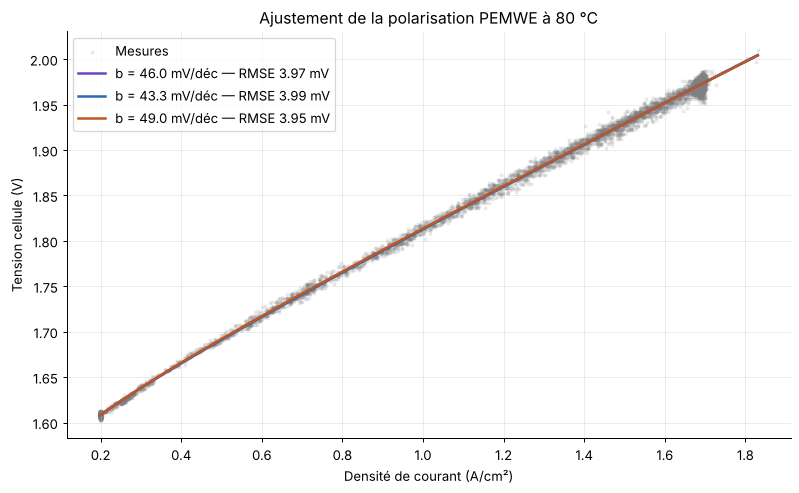

In [3]:
j_all=I/A_GEO;v_all=U/N_CELL;valid=np.isfinite(j_all)&np.isfinite(v_all)&(j_all>0)&(j_all<I_LIM)
j_exp=j_all[valid];v_exp=v_all[valid]
def voltage(j,theta,T=T_K,alpha=None):
    log_i0a,Rtot,Bc=theta;a=ALPHA_A if alpha is None else alpha;j=np.asarray(j,float)
    return E_rev(T)+R*T/(2*F*a)*np.log(j/np.exp(log_i0a))+Rtot*j-Bc*np.log1p(-j/I_LIM)
def fit(alpha=None,nstart=50,seed=180):
    rng=np.random.default_rng(seed);best=None
    lo=np.array([np.log(1e-14),0,0]);hi=np.array([np.log(1e-1),1,1])
    for _ in range(nstart):
        s=least_squares(lambda x:voltage(j_exp,x,alpha=alpha)-v_exp,rng.uniform(lo,hi),bounds=(lo,hi),max_nfev=10000)
        if best is None or np.sum(s.fun**2)<np.sum(best.fun**2):best=s
    err=voltage(j_exp,best.x,alpha=alpha)-v_exp
    return {"alpha_a":ALPHA_A if alpha is None else alpha,"i0a":np.exp(best.x[0]),"Rtot":best.x[1],"Bc":best.x[2],
            "RMSE_mV":1e3*np.sqrt(np.mean(err**2)),"MAE_mV":1e3*np.mean(abs(err)),
            "R2":1-np.sum(err**2)/np.sum((v_exp-v_exp.mean())**2),"theta":best.x}
central=fit()
fits_b=[central]+[fit(alpha_from_b(b)) for b in B_TAF_BORNES]
fits=pd.DataFrame([{"b (mV/déc)":1e3*np.log(10)*R*T_K/(2*F*q["alpha_a"]),**{k:v for k,v in q.items() if k!="theta"}} for q in fits_b])
display(fits.round(8))
I0A_0=central["i0a"];RTOT_0=central["Rtot"];BC=central["Bc"];TH0=central["theta"]
J_REF=float(np.mean(j_all));VREF0=float(voltage(J_REF,TH0));V_EOL=1.10*VREF0
act=R*T_K/(2*F*ALPHA_A)*np.log(J_REF/I0A_0);ohm=RTOT_0*J_REF;conc=-BC*np.log1p(-J_REF/I_LIM)
print(f"Cas central : i0a={I0A_0:.4e} A/cm² ; R0={1e3*RTOT_0:.1f} mOhm.cm² ; Bc={BC:.4f} V ; RMSE={central['RMSE_mV']:.2f} mV ; R2={central['R2']:.5f}")
print(f"j_ref={J_REF:.4f} A/cm² ; V_ref(0)={VREF0:.4f} V ; seuil +10 % = {V_EOL:.4f} V ; marge = {1e3*(V_EOL-VREF0):.1f} mV")
print(f"Décomposition à j_ref : E_rev={E_rev(T_K):.4f} V ; activation anode={1e3*act:.1f} mV ; ohmique={1e3*ohm:.1f} mV ; concentration={1e3*conc:.1f} mV")
idx=np.argsort(j_exp);fig,ax=plt.subplots(figsize=(9,5.6));ax.scatter(j_exp,v_exp,s=5,alpha=.12,color="gray",label="Mesures")
jg=np.linspace(j_exp.min(),j_exp.max(),700)
for q,c in zip(fits_b,["#6B46C1","#2B6CB0","#C05621"]):
    b=1e3*np.log(10)*R*T_K/(2*F*q["alpha_a"]);ax.plot(jg,voltage(jg,q["theta"],alpha=q["alpha_a"]),lw=2,color=c,label=f"b = {b:.1f} mV/déc — RMSE {q['RMSE_mV']:.2f} mV")
ax.set(xlabel="Densité de courant (A/cm²)",ylabel="Tension cellule (V)",title="Ajustement de la polarisation PEMWE à 80 °C");ax.legend();fig.tight_layout();fig.savefig(OUT/"01_ajustement_80C.png",dpi=220);plt.show()

## 3. Vieillissement à 80 °C — constantes issues de la littérature

$$f_A(t)=f_{A,\min}+(1-f_{A,\min})e^{-k_{cat}t},\qquad R_{tot}(t)=R_{tot,0}+\frac{dR}{dt}\,t,\qquad \eta_F(t)=1-\frac{1-\eta_{F,0}}{e(t)/e_0},\quad \frac{e(t)}{e_0}=1-\frac{t}{2t_{50}}.$$

| Grandeur | Optimiste | Moyen | Pessimiste | Source |
|---|---|---|---|---|
| $f_{A,\min}$ ; $1/k_{cat}$ | 0,49 ; 1,1 kh | 0,30 ; 1,05 kh | 0,112 ; 1,0 kh | Padgett et al. (2025) : surface active / activité massique de l'anode |
| $dR/dt$ (mΩ·cm²/kh) | 2,33 (HFR) | 2,90 (HFR + ½ CLR) | 3,47 (HFR + CLR) | Padgett et al. (2025), dérives à 3 A/cm² divisées par 3 A/cm² |
| $t_{50}$ membrane (h) | 110 100 | 95 400 | 80 700 | Chandesris et al. (2015), 353 K |

$f_A$ multiplie $i_{0,a}$. Comme la pente du modèle est la pente mesurée (46 mV/déc), la perte de tension vaut directement $b\log_{10}(1/f_A)$, comme chez Padgett et al. (éq. 4).

**Version 18 :** seule la colonne « Pessimiste » est utilisée dans l'étude (cas pessimiste). Statut des valeurs : $1/k_{cat}$ = 1,0 kh et la pente de 46 mV/déc sont publiés par Padgett et al. ; $f_{A,\min}$ = 0,112 = 10,4/93 est calculé (activité de fin d'essai rapportée à l'activité initiale) ; $dR/dt$ = 3,47 est calculé ; $t_{50}$ = 80 700 h est publié (modèle couplé de Chandesris et al., 353 K, 1 A/cm²). Les colonnes « Optimiste » et « Moyen » sont gardées pour mémoire : 0,49 et 1,1 kh concernent la capacité et non l'activité, 0,30 et 1,05 kh sont des moyennes, 110 100 h est le modèle de Chandesris sans couplage et 95 400 h une moyenne.

**Fin de vie** (DOE) : hausse de 10 % de la tension au courant de référence $j_{ref}$ (courant moyen du profil, 1,2 A/cm²).

In [4]:
j_base=I/A_GEO
HFR,CLR=7e-6/3.0,3.4e-6/3.0
# V18 : seul le jeu « Pessimiste » est utilisé dans l'étude ; « Optimiste » et « Moyen » sont gardés pour mémoire.
scenarios={
 "Optimiste":{"fA_min":.49,"k_cat":1/1100.,"r":HFR,"t50":110100.},
 "Moyen":{"fA_min":(.49+10.4/93)/2,"k_cat":(1/1100.+1/1000.)/2,"r":HFR+.5*CLR,"t50":95400.},
 "Pessimiste":{"fA_min":10.4/93,"k_cat":1/1000.,"r":HFR+CLR,"t50":80700.}}
colors={"Optimiste":"#2E8B57","Moyen":"#E69F00","Pessimiste":"#C44E52"}
def state(t,p):
    fa=p["fA_min"]+(1-p["fA_min"])*np.exp(-p["k_cat"]*t);rt=RTOT_0+p["r"]*t;eta=1-(1-ETA_F0)/(1-0.5*t/p["t50"])
    return fa,rt,eta
V0=voltage(j_base,TH0);VMEAN0=float(np.mean(V0))
def profile(t,p):
    fa,rt,eta=state(t,p);th=np.array([np.log(I0A_0*fa),rt,BC]);v=voltage(j_base,th)
    energy=float(np.sum(E_STEP*v/V0));h2=H20*eta/ETA_F0;sec=energy/h2
    return {"fA":fa,"Rratio":rt/RTOT_0,"etaF":eta,"V":v,"Vmean":float(np.mean(v)),"Vref":float(voltage(J_REF,th)),"E":energy,"H2":h2,"SEC":sec}
def eol(p,tmax=400000):
    g=lambda t:profile(t,p)["Vref"]-V_EOL
    return brentq(g,0,tmax) if g(tmax)>=0 else np.nan
rows=[];trajectories={}
for name,p in scenarios.items():
    te=eol(p);ages=np.linspace(0,te,301);qq=[profile(t,p) for t in ages]
    tr=pd.DataFrame({"Age_h":ages,"Vmean_V_cell":[x["Vmean"] for x in qq],"Energy_kWh":[x["E"] for x in qq],"H2_kg":[x["H2"] for x in qq],"SEC_kWh_kg":[x["SEC"] for x in qq],"etaF":[x["etaF"] for x in qq],"fA":[x["fA"] for x in qq],"R_ratio":[x["Rratio"] for x in qq]});trajectories[name]=tr;q=qq[-1]
    dvc=1e3*B_TAF*np.log10(1/p["fA_min"])
    rows.append({"Scenario":name,"EoL_h":te,"EoL_main_h":(V_EOL-VREF0-dvc/1e3)/(p["r"]*J_REF),"dV_cin_plateau_mV":dvc,"taux_uV_h":1e6*(V_EOL-VREF0)/te,
                 "Vref0":VREF0,"Vref_EOL":q["Vref"],"fA_EOL":q["fA"],"R_ratio_EOL":q["Rratio"],"etaF_EOL_pct":100*q["etaF"],
                 "H2_EOL_kg":q["H2"],"SEC0":SEC0,"SEC_EOL":q["SEC"],"Hausse_SEC_pct":100*(q["SEC"]/SEC0-1)})
results=pd.DataFrame(rows).set_index("Scenario");display(results.round(4))

,EoL_h,EoL_main_h,dV_cin_plateau_mV,taux_uV_h,Vref0,Vref_EOL,fA_EOL,R_ratio_EOL,etaF_EOL_pct,H2_EOL_kg,SEC0,SEC_EOL,Hausse_SEC_pct
Scenario,,,,,,,,,,,,,
Optimiste,61311.4556,61311.4556,14.2510,3.0337,1.86,2.046,0.4900,1.6637,96.8054,52.4486,53.6756,60.6692,13.0293
Moyen,46533.2759,46533.2759,23.9917,3.9972,1.86,2.046,0.3009,1.6261,96.9514,52.5277,53.6756,60.5050,12.7233
Pessimiste,34175.4069,34175.4069,43.7667,5.4425,1.86,2.046,0.1118,1.5496,97.0757,52.5950,53.6756,60.2797,12.3036


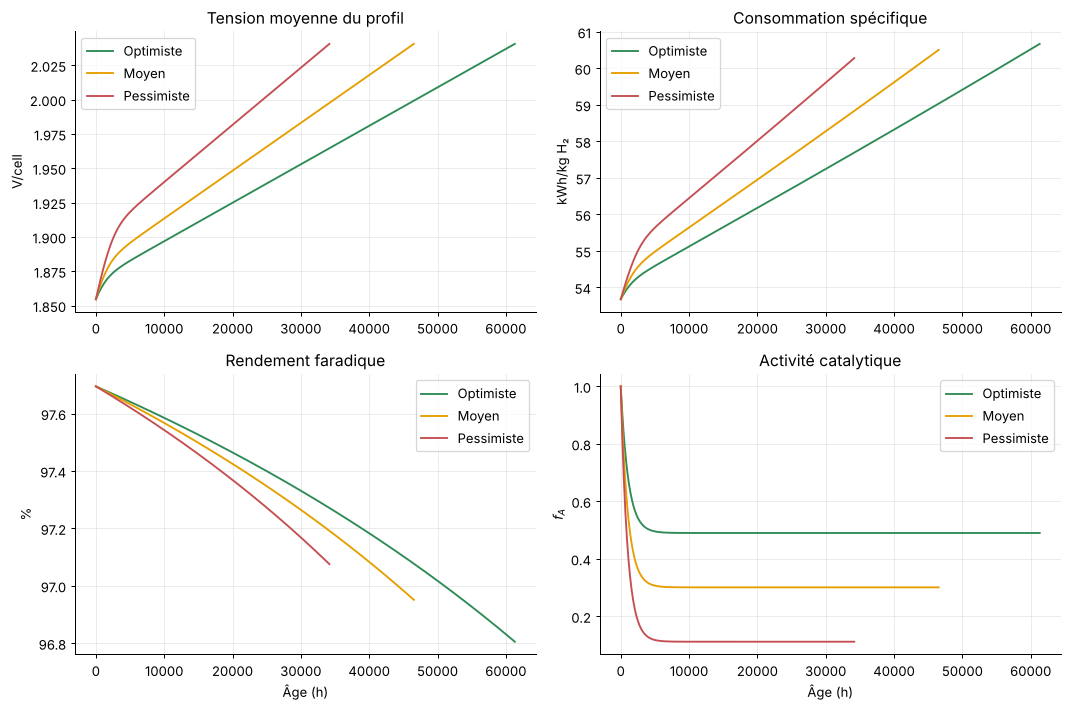

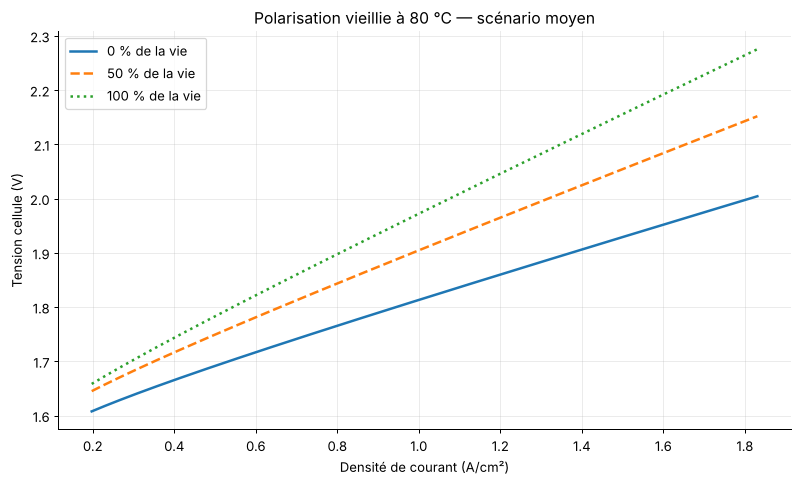

In [5]:
fig,axs=plt.subplots(2,2,figsize=(12,8))
for name,tr in trajectories.items():
    axs[0,0].plot(tr.Age_h,tr.Vmean_V_cell,label=name,color=colors[name]);axs[0,1].plot(tr.Age_h,tr.SEC_kWh_kg,label=name,color=colors[name])
    axs[1,0].plot(tr.Age_h,100*tr.etaF,label=name,color=colors[name]);axs[1,1].plot(tr.Age_h,tr.fA,label=name,color=colors[name])
axs[0,0].set(title="Tension moyenne du profil",ylabel="V/cell");axs[0,1].set(title="Consommation spécifique",ylabel="kWh/kg H₂")
axs[1,0].set(title="Rendement faradique",xlabel="Âge (h)",ylabel="%");axs[1,1].set(title="Activité catalytique",xlabel="Âge (h)",ylabel="$f_A$")
for ax in axs.flat:ax.legend()
fig.tight_layout();fig.savefig(OUT/"03_vieillissement_80C.png",dpi=220);plt.show()
fig,ax=plt.subplots(figsize=(9,5.5));jg=np.linspace(max(.02,j_base.min()),min(I_LIM*.995,j_base.max()),500)
p=scenarios["Moyen"];te=results.loc["Moyen","EoL_h"]
for frac,ls in [(0,"-"),(.5,"--"),(1,":")]:
    fa,rt,_=state(frac*te,p);ax.plot(jg,voltage(jg,np.array([np.log(I0A_0*fa),rt,BC])),ls=ls,lw=2,label=f"{frac*100:.0f} % de la vie")
ax.set(xlabel="Densité de courant (A/cm²)",ylabel="Tension cellule (V)",title="Polarisation vieillie à 80 °C — scénario moyen");ax.legend();fig.tight_layout();fig.savefig(OUT/"04_polarisation_vieillie_80C.png",dpi=220);plt.show()

In [6]:
# Sensibilités : (1) membrane à 60 °C (Chandesris, 333 K) ; (2) pente de Tafel 43,3 et 49 mV/déc (modèle réajusté)
sens=[]
for name,p in scenarios.items():
    for lab,t50 in [("80 °C (central)",p["t50"]),("60 °C (333 K)",{"Optimiste":590500.,"Moyen":485500.,"Pessimiste":380500.}[name])]:
        q=dict(p);q["t50"]=t50;te=eol(q);x=profile(te,q)
        sens.append({"Scenario":name,"Cas":f"membrane {lab}","EoL_h":te,"etaF_EOL_pct":100*x["etaF"],"SEC_EOL":x["SEC"],"Hausse_SEC_pct":100*(x["SEC"]/SEC0-1)})
_save=(ALPHA_A,B_TAF,I0A_0,RTOT_0,BC,TH0,V0,VREF0,V_EOL)
for qf,b in zip(fits_b[1:],B_TAF_BORNES):
    ALPHA_A,B_TAF=qf["alpha_a"],b;I0A_0,RTOT_0,BC,TH0=qf["i0a"],qf["Rtot"],qf["Bc"],qf["theta"]
    V0=voltage(j_base,TH0);VREF0=float(voltage(J_REF,TH0));V_EOL=1.10*VREF0
    p=scenarios["Moyen"];te=eol(p);x=profile(te,p)
    sens.append({"Scenario":"Moyen","Cas":f"pente de Tafel {1e3*b:.1f} mV/déc","EoL_h":te,"etaF_EOL_pct":100*x["etaF"],"SEC_EOL":x["SEC"],"Hausse_SEC_pct":100*(x["SEC"]/SEC0-1)})
ALPHA_A,B_TAF,I0A_0,RTOT_0,BC,TH0,V0,VREF0,V_EOL=_save
sens=pd.DataFrame(sens);display(sens.round(3))

,Scenario,Cas,EoL_h,etaF_EOL_pct,SEC_EOL,Hausse_SEC_pct
0,Optimiste,membrane 80 °C (central),61311.456,96.805,60.669,13.029
1,Optimiste,membrane 60 °C (333 K),61311.456,97.569,60.195,12.145
2,Moyen,membrane 80 °C (central),46533.276,96.951,60.505,12.723
3,Moyen,membrane 60 °C (333 K),46533.276,97.579,60.116,11.998
4,Pessimiste,membrane 80 °C (central),34175.407,97.076,60.280,12.304
5,Pessimiste,membrane 60 °C (333 K),34175.407,97.586,59.964,11.716
6,Moyen,pente de Tafel 43.3 mV/déc,46928.665,96.943,60.520,12.751
7,Moyen,pente de Tafel 49.0 mV/déc,46093.955,96.961,60.489,12.693


In [7]:
# ---------------------------------------------------------------- export pour les autres notebooks
W0=float(np.sum(E_STEP/V0));WJ=float(np.sum(E_STEP*j_base/V0))
P={"T_K":T_K,"b_tafel":B_TAF,"alpha_a":ALPHA_A,"Erev":E_rev(T_K),"i0a":I0A_0,"R0":RTOT_0,"Bc":BC,"ilim":I_LIM,
   "RMSE_mV":central["RMSE_mV"],"R2":central["R2"],"j_ref":J_REF,"Vref0":VREF0,"Vmean0":VMEAN0,
   "E0":E0,"H20":H20,"SEC0":SEC0,"etaF0":ETA_F0,"W0":W0,"Wj":WJ,
   "decomposition_jref_mV":{"activation":1e3*act,"ohmique":1e3*ohm,"concentration":1e3*conc},
   "fits_pente":fits.drop(columns=[]).to_dict(orient="records"),
   "resultats":results.reset_index().to_dict(orient="records"),"sensibilites":sens.to_dict(orient="records")}
for path in [Path("pemwe_parametres.json"),OUT/"pemwe_parametres.json"]:
    json.dump(P,open(path,"w",encoding="utf-8"),ensure_ascii=False,indent=1,default=float)
print("pemwe_parametres.json écrit — à placer à côté des autres notebooks (et à m'envoyer pour mettre à jour les résultats).")
fits.to_csv(OUT/"ajustement_80C_pentes.csv",index=False,encoding="utf-8-sig")
results.to_csv(OUT/"resultats_vieillissement_80C.csv",encoding="utf-8-sig")
for name,tr in trajectories.items():tr.to_csv(OUT/f"trajectoire_{name.lower()}_80C.csv",index=False,encoding="utf-8-sig")
sens.to_csv(OUT/"sensibilites.csv",index=False,encoding="utf-8-sig")
print("Exports terminés dans",OUT.resolve())

pemwe_parametres.json écrit — à placer à côté des autres notebooks (et à m'envoyer pour mettre à jour les résultats).
Exports terminés dans ./resultats_PEMWE_temperature_vieillissement


## Limites

- Température supposée (80 °C), non mesurée ; $i_{lim}$ fixé ; pas de transitoires thermiques.
- Les constantes viennent d'un essai à 80 °C et 3 A/cm² (Padgett) : la HFR est appliquée sans correction de courant, ce qui est prudent à 1,2 A/cm².
- La perte de la cathode (quelques mV) est négligée.
- Le crossover est supposé inversement proportionnel à l'épaisseur de membrane ; toute la perte faradique initiale lui est attribuée.